In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

In [ ]:
# Original dataset has 30 rows

In [5]:
X = np.load(r"initial_data\function_7\initial_inputs.npy")
Y = np.load(r"initial_data\function_7\initial_outputs.npy")
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'x3': X[:,2],
    'x4': X[:,3],
    'x5': X[:,4],
    'x6': X[:,5],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,x3,x4,x5,x6,y
1,0.272624,0.324495,0.897109,0.832951,0.154063,0.795864,0.604433
2,0.543003,0.924694,0.341567,0.646486,0.718440,0.343133,0.562753
3,0.090832,0.661529,0.065931,0.258577,0.963453,0.640265,0.007503
4,0.118867,0.615055,0.905816,0.855300,0.413631,0.585236,0.061424
5,0.630218,0.838097,0.680013,0.731895,0.526737,0.348429,0.273047
6,0.764919,0.255883,0.609084,0.218079,0.322943,0.095794,0.083747
7,0.057896,0.491672,0.247422,0.218118,0.420428,0.730970,1.364968
8,0.195252,0.079227,0.554580,0.170567,0.014944,0.107032,0.092645
9,0.642303,0.836875,0.021793,0.101488,0.683071,0.692416,0.017870
10,0.789943,0.195545,0.575623,0.073659,0.259049,0.051100,0.033565


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[30:])+1}: {max(Y[30:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 3.2487882238430927
Corresponding x values:
 [0.161621 0.187075 0.503918 0.254813 0.334677 0.663204]
Best query output: 
 Query 12: 3.2487882238430927
Improvement over last:
 3.2487882238430927 - 2.882350692309635 = 0.3664375315334576


In [ ]:
kernel = ConstantKernel(1.0) * RBF(length_scale=0.2)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=20,
    random_state = 42
)

gp.fit(X, Y)

candidate_points = np.random.rand(10000,6)

mu, sigma = gp.predict(candidate_points, return_std=True)

best_y = np.max(Y)
xi = 0

improvement = mu - best_y - xi

Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

mean, std = gp.predict(next_point.reshape(-1,6), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.239817 0.352197 0.525174 0.248557 0.39177  0.517828]
Predicted mean: [2.6770898]
Predicted std: [0.41541219]


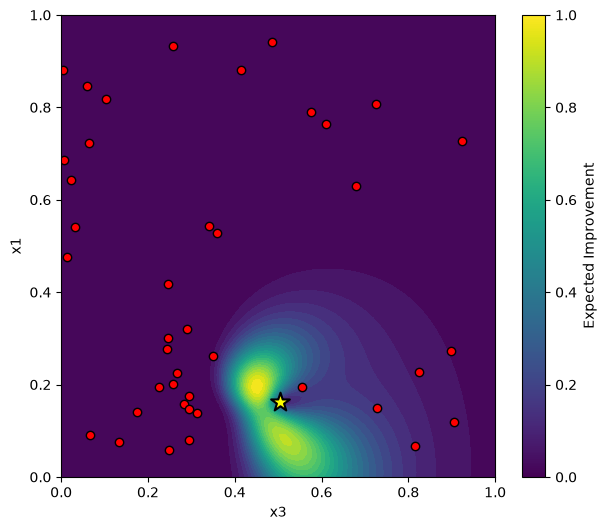

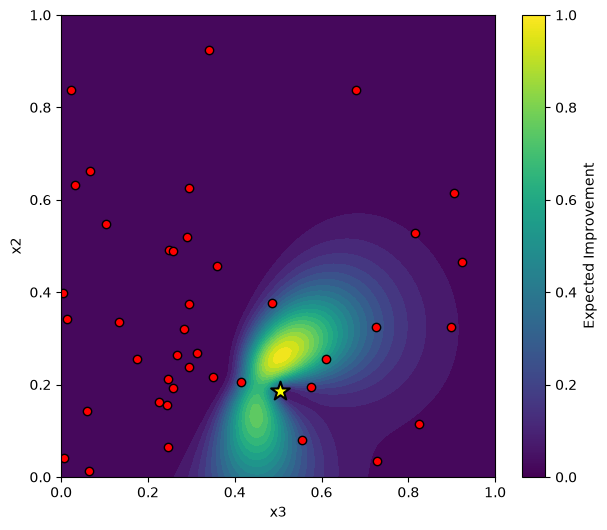

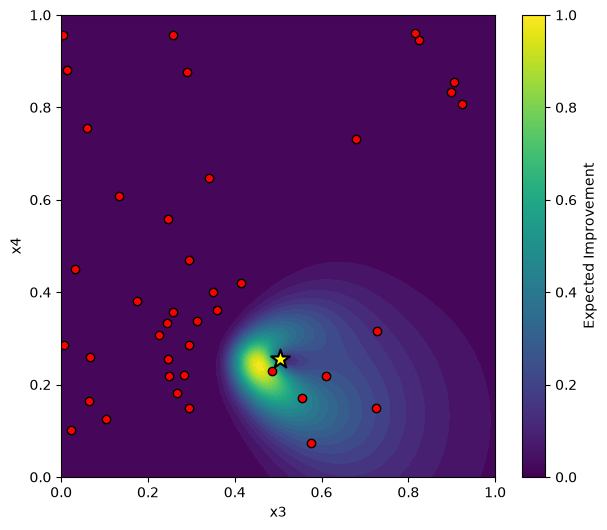

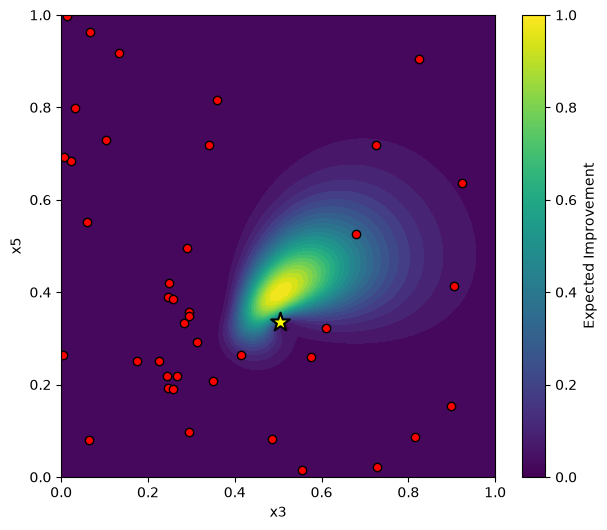

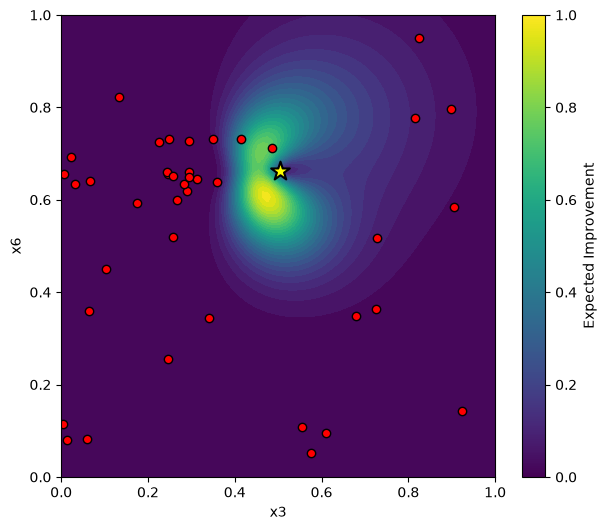

In [12]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    best_point = X[np.argmax(Y)].copy()

    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    grid = np.tile(best_point, (xx.size, 1))

    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    mu, sigma = gp.predict(grid, return_std=True)

    best_y = np.max(Y)

    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")

    plt.show()

plot_EI_slice(gp, X, Y, dim1=2, dim2=0)
plot_EI_slice(gp, X, Y, dim1=2, dim2=1)
plot_EI_slice(gp, X, Y, dim1=2, dim2=3)
plot_EI_slice(gp, X, Y, dim1=2, dim2=4)
plot_EI_slice(gp, X, Y, dim1=2, dim2=5)

In [ ]:
'''
1st point selected: [0.080871-0.374942-0.294087-0.148619-0.357409-0.659524]
Output: 1.976824478894445

2nd point selected: [0.157071-0.319628-0.282868-0.220842-0.333569-0.634601]
Output: 2.601394764183109

3rd point selected: [0.299803-0.212361-0.245356-0.254803-0.390394-0.656067]
Output: 2.5760718111146224

4th point selected: [0.276637-0.156612-0.242745-0.332914-0.219418-0.659876]
Output: 2.5857236282368983

5th point selected: [0.225119-0.264798-0.267537-0.181625-0.217647-0.599318]
Output: 2.2393918177132845

6th point selected: [0.261031-0.217256-0.349185-0.400131-0.207873-0.731896]
Output: 2.2445300524696568

7th point selected: [0.140542-0.255115-0.174225-0.381675-0.252005-0.593483]
Output: 2.2555410048690487

8th point selected: [0.202117-0.191827-0.257793-0.357006-0.385118-0.652284]
Output: 2.5900204694113715

9th point selected: [0.137351-0.268382-0.312479-0.338237-0.291102-0.645157]
Output: 2.818671537192822

10th point selected: [0.194016-0.161949-0.226307-0.307601-0.250798-0.725241]
Output: 2.7282748848673557 

11th point selected: [0.147843-0.238566-0.293837-0.284648-0.349376-0.649102]
Output: 2.882350692309635 

12th point selected: [0.161621-0.187075-0.503918-0.254813-0.334677-0.663204]
Output: 3.2487882238430927   ---NEW BEST---

Final point selected: [0.140269-0.242977-0.523698-0.180973-0.367603-0.643924]  --- xi reduced to 0, x3 reduced manually from 0.62 to 0.52 ---
Output: 2.8422582341035914

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.080871,0.374942,0.294087,0.148619,0.357409,0.659524], dtype=np.float64)
# Y_query1_output = np.array([1.976824478894445], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.157071,0.319628,0.282868,0.220842,0.333569,0.634601], dtype=np.float64)
# Y_query2_output = np.array([2.601394764183109], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.299803,0.212361,0.245356,0.254803,0.390394,0.656067], dtype=np.float64)
# Y_query3_output = np.array([2.5760718111146224], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.276637,0.156612,0.242745,0.332914,0.219418,0.659876], dtype=np.float64)
# Y_query4_output = np.array([2.5857236282368983], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.225119,0.264798,0.267537,0.181625,0.217647,0.599318], dtype=np.float64)
# Y_query5_output = np.array([2.2393918177132845], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.261031,0.217256,0.349185,0.400131,0.207873,0.731896], dtype=np.float64)
# Y_query6_output = np.array([2.2445300524696568], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.140542,0.255115,0.174225,0.381675,0.252005,0.593483], dtype=np.float64)
# Y_query7_output = np.array([2.2555410048690487], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.202117,0.191827,0.257793,0.357006,0.385118,0.652284], dtype=np.float64)
# Y_query8_output = np.array([2.5900204694113715], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.137351,0.268382,0.312479,0.338237,0.291102,0.645157], dtype=np.float64)
# Y_query9_output = np.array([2.818671537192822], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.194016,0.161949,0.226307,0.307601,0.250798,0.725241], dtype=np.float64)
# Y_query10_output = np.array([2.7282748848673557], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.147843,0.238566,0.293837,0.284648,0.349376,0.649102], dtype=np.float64)
# Y_query11_output = np.array([2.882350692309635], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.161621,0.187075,0.503918,0.254813,0.334677,0.663204], dtype=np.float64)
# Y_query12_output = np.array([3.2487882238430927], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.140269,0.242977,0.523698,0.180973,0.367603,0.643924], dtype=np.float64)
# Y_query13_output = np.array([2.8422582341035914], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_7\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_7\initial_outputs.npy", Y_updated)